# Customer journey analytics

Business question: where do observed visitors leave the shopping journey? Use audited Retailrocket data, explicit SQL denominators and temporal metadata. [Source and attribution](https://www.kaggle.com/datasets/retailrocket/ecommerce-dataset): Retailrocket, CC BY-NC-SA 4.0. Data was not collected by the project author.

In [1]:
from pathlib import Path
import sys
import json
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
assert (ROOT / 'reports/data_quality.json').exists(), 'Run python -m src.pipeline all first'
REPORTS = ROOT / 'reports'


## 1. Audit before analysis

Structural nulls differ from missing required fields. Exact duplicate event rows are removed. The JSON contains input hashes and validations.

In [2]:
quality = json.loads((REPORTS / 'data_quality.json').read_text())
audit_rows = []
for name, stats in quality['files'].items():
    audit_rows.append({'file': name, 'rows': stats['rows'],
                       'duplicates': stats['exact_duplicate_rows'],
                       'missing_values': sum(stats['missing'].values()),
                       'UTC_start': stats.get('utc_start', 'not timestamped'),
                       'UTC_end': stats.get('utc_end', 'not timestamped')})
display(pd.DataFrame(audit_rows))
display(pd.Series(quality['files']['events.csv']['event_distribution'], name='raw_events'))
print('Event-time category coverage:', f"{quality['validation']['event_category_coverage_asof']:.2%}")


,file,rows,duplicates,missing_values,UTC_start,UTC_end
0,events.csv,2756101,460,2733644,2015-05-03 03:00:04.384000+00:00,2015-09-18 02:59:47.788000+00:00
1,item_properties_part1.csv,10999999,0,0,2015-05-10 03:00:00+00:00,2015-09-13 03:00:00+00:00
2,item_properties_part2.csv,9275903,0,0,2015-05-10 03:00:00+00:00,2015-09-13 03:00:00+00:00
3,category_tree.csv,1669,0,25,not timestamped,not timestamped


view           2664312
addtocart        69332
transaction      22457
Name: raw_events, dtype: int64

Event-time category coverage: 76.16%


## 2. SQL funnel

Require strictly increasing timestamps. This is a visitor funnel across the capture period; it can span sessions and items.

,stage,visitors
0,view,1404179
1,addtocart,32934
2,transaction,9952


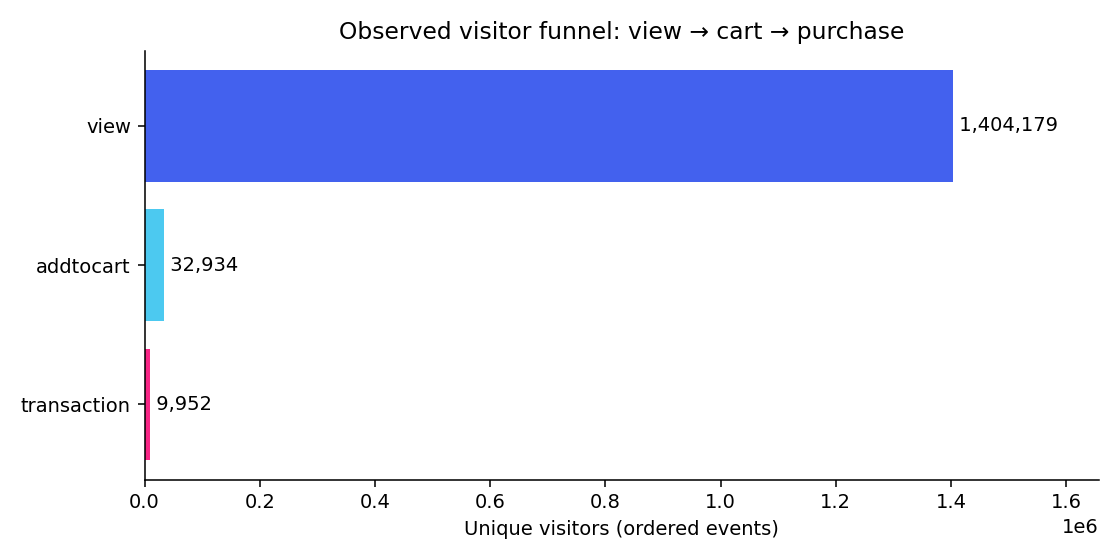

In [3]:
with sqlite3.connect(ROOT / 'data/processed/retailrocket.sqlite') as con:
    funnel = pd.read_sql_query((ROOT / 'sql/01_funnel.sql').read_text(), con)
display(funnel)
display(Image(filename=str(REPORTS / 'figures/funnel.png')))


## 3. Conversion, abandonment and returning visitors

Cart abandonment is at the cart-event level, with 24h same-item follow-up. Returning visitors are a retrospective segment, not a model feature.

In [4]:
with sqlite3.connect(ROOT / 'data/processed/retailrocket.sqlite') as con:
    display(pd.read_sql_query((ROOT / 'sql/02_conversion.sql').read_text(), con))
    display(pd.read_sql_query((ROOT / 'sql/03_returning_visitors.sql').read_text(), con))


,metric,value
0,visitor_conversion_rate,0.008326
1,24h_cart_event_abandonment_rate,0.698719
2,eligible_cart_events,68710.000000


,segment,visitors,mean_events,visitor_conversion_rate
0,returning,143769,6.425822,0.034987
1,single_day,1263811,1.449431,0.005293


## 4. Category performance and trends

Unknown categories are retained. Restrict a descriptive category table to at least 1,000 observed visitors; rate denominators overlap between categories.

,grain,entity,views,carts,transaction_events,visitors,visitor_conversion_rate
641,category,959,43450,1425,464,24030,0.013733
706,category,1051,62365,1488,421,31882,0.008500
1007,category,1483,52646,1183,369,35126,0.007715
131,category,196,22702,660,260,14385,0.015085
1042,category,1542,10380,555,248,5707,0.036622


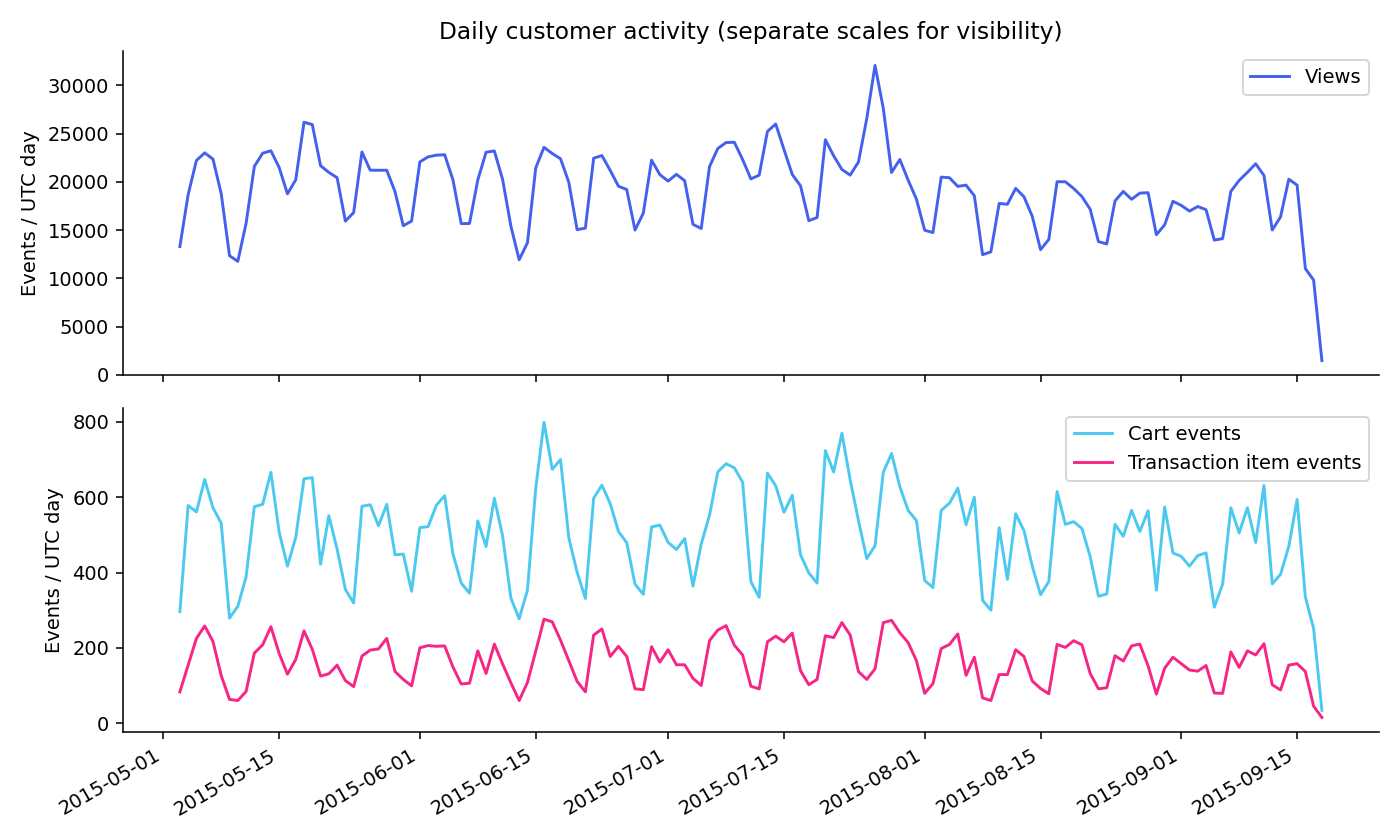

In [5]:
performance = pd.read_csv(REPORTS / '04_product_category.csv', dtype={'entity': str})
eligible = performance.query("grain == 'category' and entity != 'unknown' and visitors >= 1000")
display(eligible.nlargest(5, 'transaction_events'))
display(Image(filename=str(REPORTS / 'figures/event_trend.png')))


## 5. Product interpretation

Form hypotheses about abandonment and recurring visits, then test a reminder against a randomized no-contact holdout. High propensity does not prove uplift. Anonymous categories and missing prices cannot support product names or revenue estimates. Review `reports/results.md` for the measured results and proposed experiments.